# Dust drift in a 1D gas disk
## FTCS gas evolution, a smooth dead zone, and test particles

In the last session, we explored the effect of a dead zone in a protoplanetary disk in one dimension. I rewrote the whole program into a C program for better performance. Trust me, it's way more faster in C than in Python! And... You can explore by yourself how different parameters affect the disk evolution. Also, you can add more physics or features to the model if you like. Feel free to experiment!

In this lesson, we will explore dust drift in a 1D gas disk using this C program. The C program reads a nested YAML configuration and evolves gas and dust surface-density fields together on the same radial grid and to the same final time. Gas viscosity has a smooth, tanh-edged dead zone; the dust is advected by aerodynamic drag using the configured Stokes number. This notebook compiles and runs the C program, then plots its output.

The disk is flat, with constant aspect ratio $h=H/r=0.05$. Radius is measured in units of $r_0$, and the gas and dust equations use dimensionless quantities. The initial dust is spread over the entire grid with a constant dust-to-gas surface-density ratio.

**Model limits:** this is a 1D, one-way-coupled two-fluid model. Drag moves the dust, but dust does not push back on the gas. It also neglects turbulence, particle growth and fragmentation, and vertical settling. The Stokes number is fixed in space and time. The prescribed dead-zone viscosity is a simple teaching model, not a detailed ionization or MHD calculation.

**Requirements:** a C compiler and the libyaml development files. Install them before starting VS Code or the notebook kernel so the compiler and library paths are available.

- **Debian/Ubuntu:** `sudo apt install build-essential pkg-config libyaml-dev`
- **Fedora:** `sudo dnf install gcc pkgconf-pkg-config libyaml-devel`
- **macOS:** install Xcode Command Line Tools, then `brew install libyaml` (the notebook uses `pkg-config` if available, otherwise Homebrew's prefix). -- I tested this version only, so I trust AI that the other configurations work similarly.
- **Windows:** install MSYS2 and its UCRT64 packages `mingw-w64-ucrt-x86_64-gcc`, `mingw-w64-ucrt-x86_64-pkgconf`, and `mingw-w64-ucrt-x86_64-libyaml`. Add `C:\\msys64\\ucrt64\\bin` to `PATH` before launching VS Code. Alternatively, use MSVC Build Tools, run `vcpkg install libyaml:x64-windows`, set `VCPKG_ROOT`, and start VS Code from a Visual Studio Developer environment.

## 1. Physical model -- call back from the previous notebook

As a reminder from the previous notebook, the gas surface density follows the viscous thin-disk equation, written on a uniform grid in $x=\sqrt{r}$:

$$\frac{\partial\Sigma}{\partial t}=\frac{3}{4x^3}\frac{\partial^2}{\partial x^2}(\nu\Sigma x).$$

The dead zone reduces $\alpha$ between $r=5r_0$ and $15r_0$. Its two smooth edges use the same tanh construction as in the gas-disk notebook:

$$\alpha(r)=\alpha_{\rm active}\left[1-(1-f_{\rm dead})\,g_{\rm in}(r)g_{\rm out}(r)\right],$$

$$g_{\rm in}=\frac{1}{2}\left[1+\tanh\left(\frac{r-r_{\rm in}}{w}\right)\right],\qquad
g_{\rm out}=\frac{1}{2}\left[1+\tanh\left(\frac{r_{\rm out}-r}{w}\right)\right].$$

For the flat disk, $\nu=\alpha h^2r^2\Omega_K$. The pressureless dust fluid obeys the radial continuity equation

$$\frac{\partial\Sigma_d}{\partial t}+\frac{1}{r}\frac{\partial}{\partial r}\left(r\Sigma_d v_{d,r}\right)=0,$$

where the radial velocity is

$$v_{d,r}=\frac{v_{g,r}-2\,\mathrm{St}\,\eta v_K}{1+\mathrm{St}^2},\qquad
\eta=-\frac{1}{2}h^2\frac{d\ln P}{d\ln r}.$$

### The problem: the rapid inward drift of dust material (within a timescale of a few tens or hundreds of thousand years -- callback from Exobolygók 1)

Gas is supported not only by rotation but also by its pressure gradient. In a usual disk the pressure decreases outwards, so pressure supplies part of the inward force needed for circular motion. The gas therefore rotates slightly **slower** than the Keplerian speed, approximately $v_{\phi,g}\simeq v_K(1-\eta)$ when $\eta\ll1$. A solid particle does not feel pressure directly; without drag it would orbit nearly at $v_K$. The relative azimuthal motion makes drag exchange angular momentum between gas and dust. In the usual outward-decreasing pressure profile, dust loses angular momentum and drifts inward.

The dimensionless Stokes number is $\mathrm{St}=t_{\rm stop}\Omega_K$, where $t_{\rm stop}$ is the aerodynamic stopping time and $\Omega_K=v_K/r$ is the local orbital frequency. It compares how quickly drag changes a particle's velocity with how quickly it orbits; it is **not itself a grain size**. In a real disk, the same grain can have a changing Stokes number as the gas density changes. Here St is held constant so that we can isolate how coupling strength affects the drift.

The pressure term is $\eta=-\tfrac12 h^2\,d\ln P/d\ln r$. Thus $\eta>0$ when pressure decreases with radius, and the term $-2\,\mathrm{St}\,\eta v_K$ drives inward drift. Where the pressure gradient becomes small, this contribution weakens; at a pressure maximum it changes sign across the maximum, so particles on either side tend to drift towards it. Such a pressure maximum can act as a dust trap, although this simplified calculation does not include feedback of concentrated dust on the gas.

The velocity formula combines this pressure-driven motion with radial gas accretion. For $\mathrm{St}\ll1$, the denominator is close to one and dust nearly follows the gas. For $\mathrm{St}\sim1$, the pressure-driven part is largest: $2\,\mathrm{St}/(1+\mathrm{St}^2)$ peaks at one when St is one. For $\mathrm{St}\gg1$, drag is too weak to change the orbit efficiently and the drift speed decreases roughly as $1/\mathrm{St}$. These comparisons assume the gas radial speed is not dominating the pressure-driven term.

The dead zone affects the readial motion of dust particles. Decreasing viscosity changes how the gas surface density evolves, which alters both the gas radial velocity and the pressure gradient used in the drift formula. Note however that a low-viscosity annulus is not automatically a dust trap! We need a pressure maximum (or a change in the sign of the pressure gradient) in the final profile to be able to halt inward drift.

In order to study dust drift in the presence of a dead zone, we need to specify the disk structure and dust properties. For this purpose, we use nested config file, that is, a configuration file with hierarchical sections, which are read directly by C from `Dust_drift.yaml`: `grid`, `dead_zone`, and `dust` contain the settings to change for this exercise.

## 2. Configure and run the C program

In the last session, we checked the gas disk structure and the effects of a dead zone on the gas surface density and radial velocity in a Python notebook. The simple update is now written in C, with the main fields kept explicit: gas $\Sigma_g$, pressure $P$, pressure gradient $dP/dr$, and dust $\Sigma_d$.

Edit `Dust_drift.yaml` to change the grid, dead zone, common end time, Stokes number, or initial dust-to-gas ratio. Initially, $\Sigma_d=\epsilon\Sigma_g$ in every grid cell, so there is no single particle `initial_radius`. On every common timestep the code updates the gas, recalculates $P$ and $dP/dr$, then advects dust using the current gas fields. Dust is passive: it does not alter the gas update.

**Which compiler is used?** On Linux and macOS, the notebook looks for GCC or Clang. On Windows, it first supports GCC/Clang from MSYS2/MinGW-w64; these are GNU-family compilers, **not MSVC**. The MSVC fallback is only for Windows, and requires Visual Studio Build Tools plus libyaml from vcpkg. MSVC is not a Linux compiler.

In the code below, `PATH` is the operating-system search path used to find programs such as `gcc`, `pkg-config`, and `cl.exe`. `pkg-config` reads libyaml's installation metadata and supplies its header (`-I`) and library (`-L`, `-l`) flags. The MSYS2 *prefix* is the folder for a particular toolchain, such as `C:\\msys64\\ucrt64`. For MSVC, `VCPKG_ROOT` points to the vcpkg installation, while the *triplet* (for example `x64-windows`) identifies the target architecture and library variant. The notebook uses the triplet to locate `yaml.h` and `yaml.lib`.

In [10]:
import csv
import os
import shutil
import subprocess
import sys
import tempfile
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np

plt.rcParams["figure.figsize"] = (8, 4.5)
c_source = Path("Dust_drift.c").resolve()
config_file = Path("Dust_drift.yaml").resolve() # Path to the YAML configuration file
# os.name identifies the operating-system family; MSVC is considered only on Windows.
is_windows = os.name == "nt"
# which() searches PATH, so the compiler must be installed and visible when the kernel starts.
compiler = next((shutil.which(name) for name in ("gcc", "clang", "cc") if shutil.which(name)), None)
# GCC/Clang use -I/-L/-l flags; MSVC (cl.exe) uses a different command-line syntax.
compiler_kind = "gnu" if compiler else None
if compiler is None and is_windows and shutil.which("cl"):
    compiler = shutil.which("cl")
    compiler_kind = "msvc"

# Now check the critical parts...
if compiler is None:
    # Raise an error if no C compiler is found
    raise RuntimeError("No supported C compiler found. Install GCC/Clang, or on Windows install MinGW-w64 or MSVC Build Tools.")
if not c_source.is_file():
    # Raise an error if the C source file is not found
    raise FileNotFoundError(f"C source file not found: {c_source}")
if not config_file.is_file():
    # Raise an error if the YAML config file is not found
    raise FileNotFoundError(f"YAML config file not found: {config_file}")

# pkg-config/pkgconf reads libyaml's .pc metadata and returns the right include and linker flags.
pkg_config = shutil.which("pkg-config") or shutil.which("pkgconf")
yaml_flags = None
msvc_yaml_paths = None
if pkg_config is not None and compiler_kind == "gnu":
    # --cflags tells the compiler where yaml.h is; --libs tells the linker which library to link.
    cflags = subprocess.run(
        [pkg_config, "--cflags", "yaml-0.1"], capture_output=True, text=True
    )
    libraries = subprocess.run(
        [pkg_config, "--libs", "yaml-0.1"], capture_output=True, text=True
    )
    # Keep these flags only when both queries succeeded; otherwise try the OS-specific fallback.
    if cflags.returncode == 0 and libraries.returncode == 0:
        yaml_flags = (cflags.stdout.split(), libraries.stdout.split())

# macOS fallback: Homebrew's prefix is the installation root containing include/ and lib/.
if yaml_flags is None and sys.platform == "darwin":
    brew = shutil.which("brew")
    if brew is None:
        yaml_prefix = None
    else:
        yaml_prefix = Path(subprocess.run(
            [brew, "--prefix", "libyaml"], capture_output=True, text=True, check=True
        ).stdout.strip())
        if (yaml_prefix / "include" / "yaml.h").is_file():
            yaml_flags = ([f"-I{yaml_prefix / 'include'}"], [f"-L{yaml_prefix / 'lib'}", "-lyaml"])

# Windows + GCC fallback: MSYS2 installs each toolchain in a prefix such as ucrt64 or mingw64.
if yaml_flags is None and is_windows and compiler_kind == "gnu":
    # These environment variables are set by some MSYS2 shells; the paths cover common defaults.
    msys_prefixes = [os.environ.get("MSYSTEM_PREFIX"), os.environ.get("MSYS2_PREFIX"),
                     r"C:\msys64\ucrt64", r"C:\msys64\mingw64", r"C:\msys64\clang64"]
    yaml_prefix = next((Path(p) for p in msys_prefixes if p and (Path(p) / "include" / "yaml.h").is_file()), None)
    if yaml_prefix is not None:
        yaml_flags = ([f"-I{yaml_prefix / 'include'}"], [f"-L{yaml_prefix / 'lib'}", "-lyaml"])

# Windows + MSVC fallback: vcpkg installs libraries under installed/<triplet>/.
if yaml_flags is None and compiler_kind == "msvc":
    # VCPKG_ROOT is the vcpkg checkout; the triplet selects target architecture and library variant.
    vcpkg_root = os.environ.get("VCPKG_ROOT")
    triplet = os.environ.get("VCPKG_DEFAULT_TRIPLET", "x64-windows")
    if vcpkg_root:
        vcpkg_prefix = Path(vcpkg_root) / "installed" / triplet
        yaml_include = vcpkg_prefix / "include"
        yaml_library = vcpkg_prefix / "lib"
        if (yaml_include / "yaml.h").is_file() and (yaml_library / "yaml.lib").is_file():
            msvc_yaml_paths = (yaml_include, yaml_library)
    if msvc_yaml_paths is None:
        raise RuntimeError("For MSVC, install libyaml with vcpkg and set VCPKG_ROOT; use a Visual Studio Developer environment.")

# Stop with an actionable error rather than compiling without the YAML dependency.
if yaml_flags is None and (not compiler_kind == "msvc" or msvc_yaml_paths is None):
    raise RuntimeError("libyaml was not found. Install libyaml development files and pkg-config/pkgconf for your platform.")

# Extract the compiler and linker flags for libyaml, or use empty lists if not found.
yaml_cflags, yaml_libraries = yaml_flags if yaml_flags is not None else ([], [])
with tempfile.TemporaryDirectory(prefix="dust-drift-") as temp_dir:
    temp_path = Path(temp_dir)
    executable = temp_path / ("dust_drift.exe" if is_windows else "dust_drift")
    if compiler_kind == "msvc":
        yaml_include, yaml_library = msvc_yaml_paths
        # /I adds headers; /Fe names the executable; /link starts linker options; /LIBPATH locates yaml.lib.
        compile_command = [compiler, "/nologo", "/O2", "/std:c11", f"/I{yaml_include}",
                           str(c_source), f"/Fe:{executable}", "/link",
                           f"/LIBPATH:{yaml_library}", "yaml.lib"]
    else:
        # -I adds headers; -L locates libraries; -lyaml links libyaml; -lm links math functions.
        compile_command = [compiler, "-O2", "-std=c99", *yaml_cflags, str(c_source),
                           *yaml_libraries, "-lm", "-o", str(executable)]
    # Compile inside the temporary folder so object files and generated CSVs do not clutter the project.
    subprocess.run(compile_command, cwd=temp_path, check=True)
    result = subprocess.run(
        [str(executable), str(config_file)],
        cwd=temp_path,
        check=True,
        capture_output=True,
        text=True,
    )
    print(result.stdout)
    gas = np.loadtxt(temp_path / "gas.csv", delimiter=",", skiprows=1)
    gas_snapshots = np.loadtxt(temp_path / "gas_snapshots.csv", delimiter=",", skiprows=1)
    dust = np.loadtxt(temp_path / "dust.csv", delimiter=",", skiprows=1)
    dust_snapshots = np.loadtxt(temp_path / "dust_snapshots.csv", delimiter=",", skiprows=1)
    with (temp_path / "parameters.csv").open(newline="") as parameter_file:
        parameters = {
            row["name"]: float(row["value"])
            for row in csv.DictReader(parameter_file)
        }

# Extract columns from the gas and dust arrays for easier access.
r = gas[:, 0]
sigma_g, pressure, dpdr = gas[:, 1], gas[:, 2], gas[:, 3]
v_gas, alpha_profile = gas[:, 4], gas[:, 5]
sigma_d_initial, sigma_d_final, v_dust = dust[:, 1], dust[:, 2], dust[:, 3]
print(
    f"Grid: {int(parameters['n_grid'])} cells, "
    f"r={parameters['r_inner']:g}–{parameters['r_outer']:g}; "
    f"St={parameters['stokes_number']:g}; t_end={parameters['t_end']:g}; "
    f"final dust/gas ratio={sigma_d_final[-1] / sigma_g[-1]:.3g} at outer edge"
)

Gas and dust evolved together to t = 1000 years.
St = 0.1; initial dust-to-gas ratio = 0.01.
Gas stability limit = 0.005783; smallest common timestep = 0.0007365.

Grid: 180 cells, r=0.5–40; St=0.1; t_end=1000; final dust/gas ratio=1.8e-05 at outer edge


## 3. Gas evolution and dead zone

The three plots, stacked vertically, show the gas surface-density evolution, dust surface-density evolution, and imposed viscosity reduction. Both fluids use the same initial/middle/final times and grid; the arrays are written by the C program.

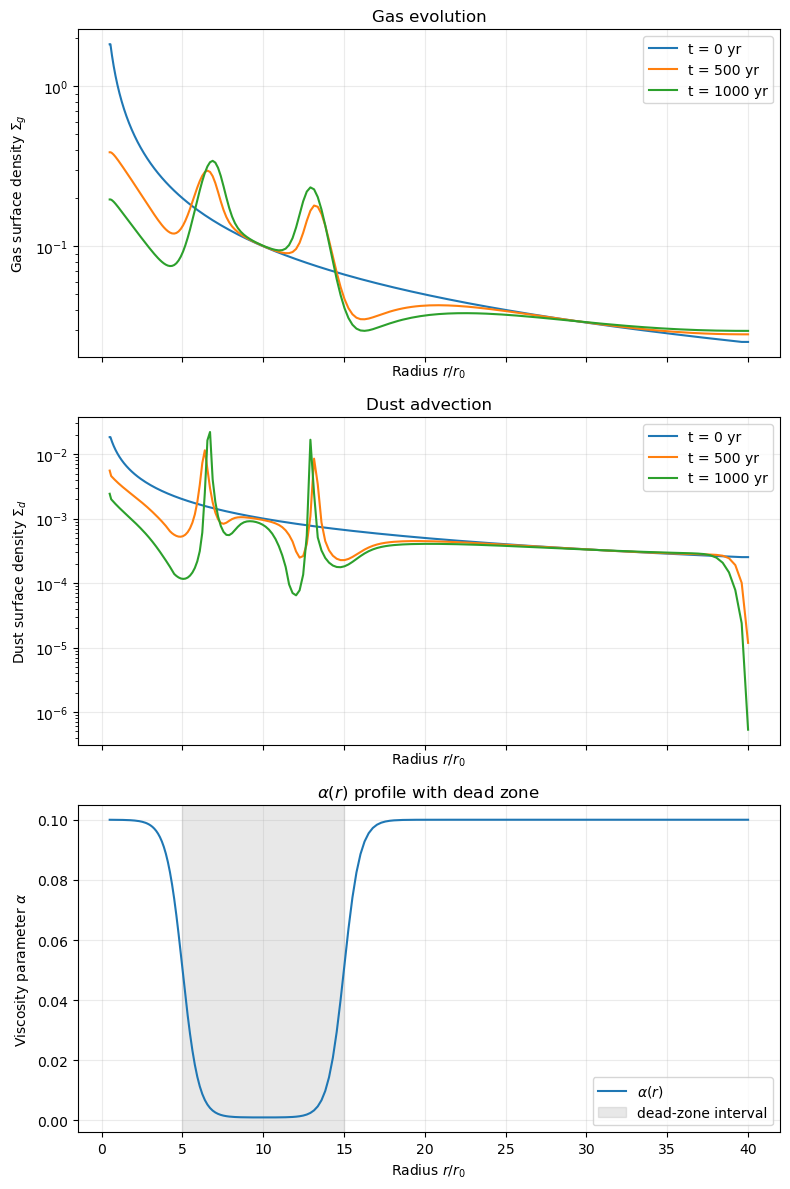

In [11]:
fig, axes = plt.subplots(3, 1, figsize=(8, 12), sharex=True)
snapshot_times = (0.0, 0.5 * parameters["t_end"], parameters["t_end"])
for column, time in zip((1, 2, 3), snapshot_times):
    axes[0].plot(gas_snapshots[:, 0], gas_snapshots[:, column], label=f"t = {time:g} yr")
axes[0].set_xlabel(r"Radius $r/r_0$")
axes[0].set_ylabel(r"Gas surface density $\Sigma_g$")
axes[0].set_title("Gas evolution")
axes[0].set_yscale("log")
axes[0].legend()
axes[0].grid(alpha=0.25)

for column, time in zip((1, 2, 3), snapshot_times):
    axes[1].plot(dust_snapshots[:, 0], dust_snapshots[:, column], label=f"t = {time:g} yr")
axes[1].set_xlabel(r"Radius $r/r_0$")
axes[1].set_ylabel(r"Dust surface density $\Sigma_d$")
axes[1].set_title("Dust advection")
axes[1].set_yscale("log")
axes[1].legend()
axes[1].grid(alpha=0.25)

axes[2].plot(r, alpha_profile, label=r"$\alpha(r)$")
axes[2].axvspan(parameters["dead_inner"], parameters["dead_outer"], color="gray", alpha=0.18, label="dead-zone interval")
axes[2].set_xlabel(r"Radius $r/r_0$")
axes[2].set_ylabel(r"Viscosity parameter $\alpha$")
axes[2].set_title(r"$\alpha(r)$ profile with dead zone")
axes[2].legend()
axes[2].grid(alpha=0.25)
plt.tight_layout()
plt.show()

**Note:** As we discussed in the last session, at the edges of the dead zone, density jumps appear. These jumps can significantly influence the dust evolution, leading to accumulation or depletion of dust particles depending on the local pressure gradient.

**Note**: It has been investigated many times that the width of the viscosity jump affects the formation time of pressure/density jumps. As we assume axisymmetricity, large-scale azimuthal variations are neglected, and the focus is on the radial structure of the disk. But! In reality, large-scale, anticyclonic vortices can form at the edges of the dead zone, further influencing the dust evolution and potentially leading to significant azimuthal asymmetries in the dust distribution.

## 4. Pressure gradient and dust drift

These final-time profiles are all read from the C output: gas pressure, $dP/dr$, and the dust velocity calculated from those fields. The zero line distinguishes inward ($v_{d,r}<0$) from outward ($v_{d,r}>0$) drift. The lower-right panel shows how the dust surface density changed from its initial grid-wide distribution.

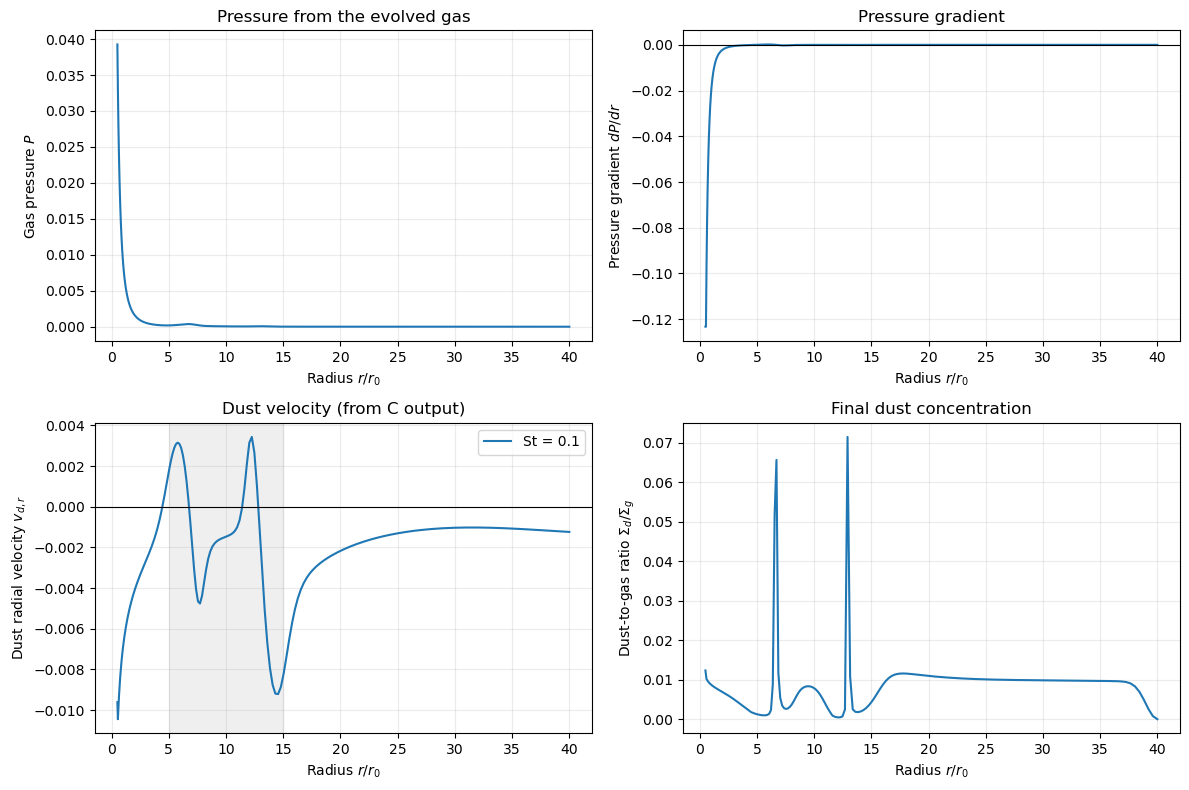

In [12]:
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
axes[0, 0].plot(r, pressure)
axes[0, 0].set_xlabel(r"Radius $r/r_0$")
axes[0, 0].set_ylabel(r"Gas pressure $P$")
axes[0, 0].set_title("Pressure from the evolved gas")
axes[0, 0].grid(alpha=0.25)

axes[0, 1].plot(r, dpdr)
axes[0, 1].axhline(0.0, color="black", linewidth=0.8)
axes[0, 1].set_xlabel(r"Radius $r/r_0$")
axes[0, 1].set_ylabel(r"Pressure gradient $dP/dr$")
axes[0, 1].set_title("Pressure gradient")
axes[0, 1].grid(alpha=0.25)

axes[1, 0].plot(r, v_dust, label=f"St = {parameters['stokes_number']:g}")
axes[1, 0].axhline(0.0, color="black", linewidth=0.8)
axes[1, 0].axvspan(parameters["dead_inner"], parameters["dead_outer"], color="gray", alpha=0.12)
axes[1, 0].set_xlabel(r"Radius $r/r_0$")
axes[1, 0].set_ylabel(r"Dust radial velocity $v_{d,r}$")
axes[1, 0].set_title("Dust velocity (from C output)")
axes[1, 0].legend()
axes[1, 0].grid(alpha=0.25)

axes[1, 1].plot(r, sigma_d_final / sigma_g)
axes[1, 1].set_xlabel(r"Radius $r/r_0$")
axes[1, 1].set_ylabel(r"Dust-to-gas ratio $\Sigma_d/\Sigma_g$")
axes[1, 1].set_title("Final dust concentration")
axes[1, 1].grid(alpha=0.25)
plt.tight_layout()
plt.show()

**Interpret:** Where does pressure decrease or increase with radius? How does that compare with the sign of the dust velocity? Where does dust accumulate, and how is that related to the dead-zone pressure structure? What changes if you increase the Stokes number or the initial dust-to-gas ratio? Remember that the dust does not feed back on the gas in this model.

## 5. Experiment

Change values in `Dust_drift.yaml` and rerun the C-program cell. Try changing `evolution.t_end`, `dead_zone.edge_width`, `dust.stokes_number`, or `dust.initial_dust_to_gas`. The C program chooses one common timestep that satisfies both the gas-diffusion and dust-advection stability limits.

The gas and dust co-evolve in time here, but the coupling is one-way. Adding dust backreaction, growth, or fragmentation would require additional equations and model assumptions.